# 06 – Deep-Learning Experiments

**Project:** Technology & Fintech Market Intelligence and Regime Analyzer  
**Phase:** 4 – Modelling and evaluation (deep learning)

### Goals
1. Load the feature panel from previous notebooks  
2. Train **more than three** sequence models (LSTM, GRU, TCN, Transformer)  
3. Use chronological splits and causal sequences only  
4. Compare against the best classical ML results from notebook 05  
5. Register models and persist metrics  

### Prerequisites
- Notebooks 01–03 completed (05 recommended for comparison)  
- `data/processed/feature_panel.parquet` (or `…_with_regimes.parquet`)  
- `data/processed/feature_metadata.json`  
- PyTorch installed

In [1]:
# Cell 1 – Imports & setup
from __future__ import annotations

import sys
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import settings
from config.constants import DL_MODELS, RANDOM_SEED
from src.utils import setup_logging, get_logger, utc_now, ensure_dir, save_json
from src.db.connection import get_client, get_db
from src.db.collections import ensure_indexes
from src.db.analysis_results import save_analysis_result

from src.models.evaluation import evaluate_regression
from src.models.dl import get_dl_model, DLTrainer, DL_MODEL_NAMES
from src.models.registry import ModelRegistry

setup_logging(level="INFO")
logger = get_logger(__name__)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Project root :", PROJECT_ROOT)
print("PyTorch      :", torch.__version__)
print("Device       :", DEVICE)
print("DL models    :", DL_MODEL_NAMES)

Project root : c:\Users\hp\Documents\GitHub\BeneathTheMarket
PyTorch      : 2.9.1+cpu
Device       : cpu
DL models    : ['lstm', 'gru', 'tcn', 'transformer']


In [2]:
## 1. Load feature panel & metadata

processed_dir = ensure_dir(settings.PROCESSED_DATA_DIR)

panel_path = processed_dir / "feature_panel_with_regimes.parquet"
if not panel_path.exists():
    panel_path = processed_dir / "feature_panel.parquet"
if not panel_path.exists():
    raise FileNotFoundError("No feature panel found. Run notebook 03 first.")

panel = pd.read_parquet(panel_path)
panel = panel.loc[:, ~panel.columns.duplicated()].copy()

import json
with open(processed_dir / "feature_metadata.json", "r", encoding="utf-8") as f:
    feature_meta = json.load(f)

HORIZON = feature_meta.get("horizon", 5)
target_ret = f"target_ret_{HORIZON}d"

feature_cols = [
    c for c in feature_meta["feature_cols"]
    if c in panel.columns and pd.api.types.is_numeric_dtype(panel[c])
]
exclude = {"regime_cluster", "regime_id"}
feature_cols = [c for c in feature_cols if c not in exclude]

print(f"Panel shape  : {panel.shape}")
print(f"Features     : {len(feature_cols)}")
print(f"Target       : {target_ret}")
print(f"Splits       : {panel['split'].value_counts().to_dict()}")

Panel shape  : (45106, 46)
Features     : 37
Target       : target_ret_5d
Splits       : {'train': 31578, 'val': 6764, 'test': 6764}


## 2. Prepare per-ticker sequences

Deep models need contiguous sequences per ticker.  
We build sequences **inside each split** so that no future data leaks  
across the train / val / test boundaries.

In [3]:
# Cell 3 – Sequence builder

SEQ_LEN = 30          # look-back window (trading days)
MIN_SEQ_ROWS = SEQ_LEN + 20

def build_split_sequences(
    df: pd.DataFrame,
    feature_cols: List[str],
    target_col: str,
    seq_len: int,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Build (X, y) sequences for one ticker-split block.
    X shape: (n_samples, seq_len, n_features)
    y shape: (n_samples,)
    """
    df = df.dropna(subset=feature_cols + [target_col]).sort_index()
    if len(df) < seq_len + 1:
        return np.empty((0, seq_len, len(feature_cols))), np.empty(0)

    X = df[feature_cols].values.astype(np.float32)
    y = df[target_col].values.astype(np.float32)

    xs, ys = [], []
    for i in range(seq_len, len(X)):
        xs.append(X[i - seq_len : i])
        ys.append(y[i])
    return np.asarray(xs, dtype=np.float32), np.asarray(ys, dtype=np.float32)


def collect_sequences(
    panel: pd.DataFrame,
    split: str,
    feature_cols: List[str],
    target_col: str,
    seq_len: int,
) -> Tuple[np.ndarray, np.ndarray]:
    """Collect sequences for every ticker inside one chronological split."""
    xs_all, ys_all = [], []
    sub = panel[panel["split"] == split]
    for ticker, grp in sub.groupby("ticker"):
        X, y = build_split_sequences(grp, feature_cols, target_col, seq_len)
        if len(X):
            xs_all.append(X)
            ys_all.append(y)
    if not xs_all:
        return np.empty((0, seq_len, len(feature_cols))), np.empty(0)
    return np.concatenate(xs_all, axis=0), np.concatenate(ys_all, axis=0)


X_train, y_train = collect_sequences(panel, "train", feature_cols, target_ret, SEQ_LEN)
X_val,   y_val   = collect_sequences(panel, "val",   feature_cols, target_ret, SEQ_LEN)
X_test,  y_test  = collect_sequences(panel, "test",  feature_cols, target_ret, SEQ_LEN)

print(f"Train sequences : {X_train.shape}")
print(f"Val   sequences : {X_val.shape}")
print(f"Test  sequences : {X_test.shape}")

if len(X_train) < 100 or len(X_test) < 20:
    raise RuntimeError("Not enough sequences – reduce SEQ_LEN or check data coverage.")

Train sequences : (28044, 30, 37)
Val   sequences : (5624, 30, 37)
Test  sequences : (5624, 30, 37)


In [4]:
## 3. Scale features (fit on train only)

from sklearn.preprocessing import StandardScaler

# Scale each feature across the time dimension using train statistics
n_features = X_train.shape[-1]
scaler = StandardScaler()

# Fit on flattened train sequences
scaler.fit(X_train.reshape(-1, n_features))

def scale_sequences(X: np.ndarray) -> np.ndarray:
    if len(X) == 0:
        return X
    shape = X.shape
    return scaler.transform(X.reshape(-1, shape[-1])).reshape(shape).astype(np.float32)

X_train_s = scale_sequences(X_train)
X_val_s   = scale_sequences(X_val)
X_test_s  = scale_sequences(X_test)

print("Scaling done.")

Scaling done.


## 4. Train deep-learning models

Models: **LSTM, GRU, TCN, Transformer**  
Early stopping on validation loss; final metrics on the held-out test set.

In [5]:
# Cell 5 – DL training loop

from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn

DL_TO_RUN = ["lstm", "gru", "tcn", "transformer"]
EPOCHS = 25
BATCH_SIZE = 128
LR = 1e-3
PATIENCE = 6
HIDDEN = 64

def train_one_model(
    name: str,
    X_tr: np.ndarray,
    y_tr: np.ndarray,
    X_va: np.ndarray,
    y_va: np.ndarray,
    X_te: np.ndarray,
    y_te: np.ndarray,
) -> Dict[str, Any]:
    model = get_dl_model(
        name,
        input_size=X_tr.shape[-1],
        hidden_size=HIDDEN,
        num_layers=2,
        dropout=0.2,
    ).to(DEVICE)

    opt = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.MSELoss()

    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)),
        batch_size=BATCH_SIZE,
        shuffle=False,
    )
    val_loader = None
    if len(X_va):
        val_loader = DataLoader(
            TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va)),
            batch_size=BATCH_SIZE,
            shuffle=False,
        )

    best_val = float("inf")
    best_state = None
    patience_ctr = 0
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            pred = model(xb).squeeze(-1)
            loss = criterion(pred, yb)
            loss.backward()
            opt.step()
            train_loss += loss.item() * len(xb)
        train_loss /= len(train_loader.dataset)

        val_loss = train_loss
        if val_loader is not None:
            model.eval()
            val_loss = 0.0
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                    pred = model(xb).squeeze(-1)
                    val_loss += criterion(pred, yb).item() * len(xb)
            val_loss /= len(val_loader.dataset)

        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val - 1e-6:
            best_val = val_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= PATIENCE:
                logger.info("%s early stop at epoch %d", name, epoch)
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    # Test evaluation
    model.eval()
    with torch.no_grad():
        pred_te = model(torch.from_numpy(X_te).to(DEVICE)).squeeze(-1).cpu().numpy()

    metrics = evaluate_regression(y_te, pred_te, prefix="test_")
    metrics["best_val_loss"] = float(best_val)
    metrics["epochs_run"] = len(history)

    return {
        "model": model,
        "metrics": metrics,
        "history": history,
        "state_dict": best_state,
    }


dl_results = {}
registry = ModelRegistry(model_type="dl")

for name in DL_TO_RUN:
    print(f"\n>>> Training {name.upper()} ...")
    try:
        out = train_one_model(
            name, X_train_s, y_train, X_val_s, y_val, X_test_s, y_test
        )
        metrics = out["metrics"]

        # Register (store state dict + scaler + meta)
        artifact = {
            "model_state": out["state_dict"],
            "model_name": name,
            "input_size": X_train.shape[-1],
            "hidden_size": HIDDEN,
            "seq_len": SEQ_LEN,
            "scaler_mean": scaler.mean_.tolist(),
            "scaler_scale": scaler.scale_.tolist(),
            "feature_cols": feature_cols,
        }
        model_id = registry.register(
            artifact,
            name=name,
            metrics=metrics,
            params={
                "seq_len": SEQ_LEN,
                "hidden_size": HIDDEN,
                "epochs": EPOCHS,
                "lr": LR,
                "batch_size": BATCH_SIZE,
            },
            feature_cols=feature_cols,
            target=target_ret,
            horizon=HORIZON,
        )
        metrics["model_id"] = model_id
        dl_results[name] = {"metrics": metrics, "history": out["history"]}
        print(f"  test_rmse={metrics['test_rmse']:.5f}  "
              f"dir_acc={metrics['test_directional_accuracy']:.3f}  "
              f"epochs={metrics['epochs_run']}")
    except Exception as exc:
        logger.warning("DL model %s failed: %s", name, exc)
        dl_results[name] = {"error": str(exc)}


>>> Training LSTM ...
2026-10-12 12:53:30 | INFO     | __main__ | lstm early stop at epoch 10
2026-10-12 12:53:30 | INFO     | src.models.registry | Saved model artifact → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\models\dl\lstm_20261012_072330_8167168e.joblib
2026-10-12 12:53:30 | INFO     | src.db.connection | Connected to local MongoDB at mongodb://localhost:27017 (db=tech_fintech_market_intel)
2026-10-12 12:53:30 | INFO     | src.models.registry | Registered model_id=lstm_20261012_072330_8167168e  (RMSE/metric keys=['test_mae', 'test_rmse', 'test_r2', 'test_mape', 'test_directional_accuracy', 'test_n_samples', 'best_val_loss', 'epochs_run'])
  test_rmse=0.08809  dir_acc=0.500  epochs=10

>>> Training GRU ...
2026-10-12 12:56:49 | INFO     | __main__ | gru early stop at epoch 11
2026-10-12 12:56:50 | INFO     | src.models.registry | Saved model artifact → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\models\dl\gru_20261012_072650_2eaf9958.joblib
2026-10-12 12:56:50 | 

Deep-learning test results:


,test_rmse,test_mae,test_r2,dir_acc,best_val_loss,epochs
model,,,,,,
transformer,0.08675,0.06121,-0.03946,0.49075,0.00365,10
gru,0.08745,0.06182,-0.05626,0.51511,0.00371,11
lstm,0.08809,0.06224,-0.07192,0.49982,0.00373,10
tcn,0.09098,0.06557,-0.14324,0.52169,0.00421,15


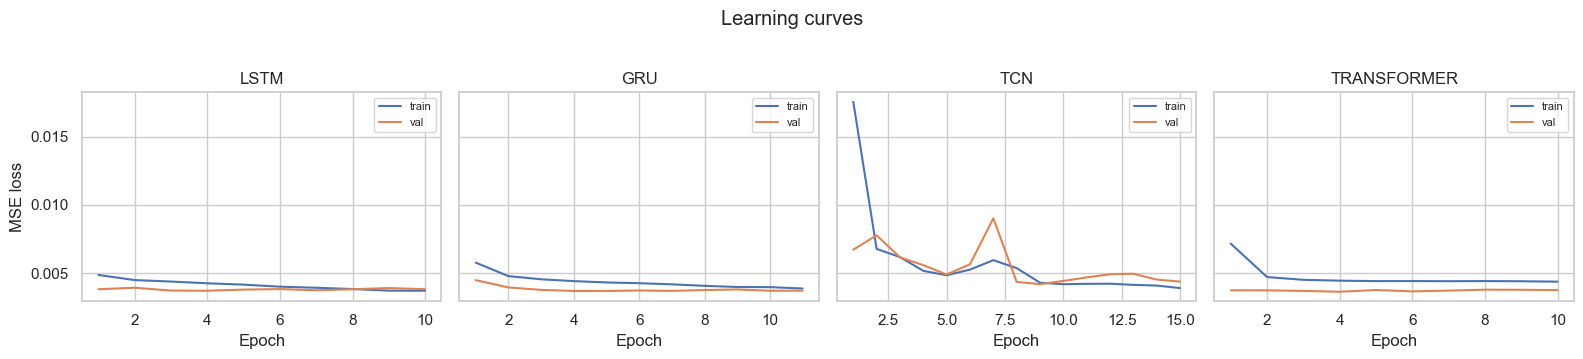

In [6]:
## 5. Results table & learning curves

rows = []
for name, res in dl_results.items():
    if "error" in res:
        continue
    m = res["metrics"]
    rows.append({
        "model": name,
        "test_rmse": m.get("test_rmse"),
        "test_mae": m.get("test_mae"),
        "test_r2": m.get("test_r2"),
        "dir_acc": m.get("test_directional_accuracy"),
        "best_val_loss": m.get("best_val_loss"),
        "epochs": m.get("epochs_run"),
    })

dl_df = pd.DataFrame(rows).set_index("model").sort_values("test_rmse")
print("Deep-learning test results:")
display(dl_df.round(5))

# Learning curves
fig, axes = plt.subplots(1, len(dl_results), figsize=(4 * max(len(dl_results), 1), 3.5), sharey=True)
if len(dl_results) == 1:
    axes = [axes]
for ax, (name, res) in zip(axes, dl_results.items()):
    if "error" in res:
        ax.set_title(f"{name} (failed)")
        continue
    hist = pd.DataFrame(res["history"])
    ax.plot(hist["epoch"], hist["train_loss"], label="train")
    ax.plot(hist["epoch"], hist["val_loss"], label="val")
    ax.set_title(name.upper())
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)
axes[0].set_ylabel("MSE loss")
plt.suptitle("Learning curves", y=1.02)
plt.tight_layout()
plt.show()

In [8]:
## 7. Persist experiment results

results_doc = {
    "run_at": utc_now().isoformat(),
    "horizon": HORIZON,
    "seq_len": SEQ_LEN,
    "hidden_size": HIDDEN,
    "n_features": len(feature_cols),
    "n_train_seq": int(len(X_train)),
    "n_val_seq": int(len(X_val)),
    "n_test_seq": int(len(X_test)),
    "device": DEVICE,
    "models": {
        k: (v["metrics"] if "metrics" in v else v)
        for k, v in dl_results.items()
    },
}

results_path = processed_dir / "dl_experiment_results.json"
save_json(results_doc, results_path)
print(f"Saved DL results → {results_path}")

save_analysis_result({
    "analysis_type": "dl_experiments",
    "as_of": utc_now().isoformat(),
    "payload": {
        "horizon": HORIZON,
        "seq_len": SEQ_LEN,
        "n_models": len([v for v in dl_results.values() if "error" not in v]),
        "best_rmse": float(dl_df["test_rmse"].min()) if len(dl_df) else None,
        "best_model": str(dl_df["test_rmse"].idxmin()) if len(dl_df) else None,
    },
})
print("DL experiment summary written to MongoDB")

Saved DL results → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\dl_experiment_results.json
DL experiment summary written to MongoDB


## 8. Acceptance criteria (Notebook 06)

| Criterion | Status |
|-----------|--------|
| ≥ 3 DL architectures evaluated | Cell 5 (LSTM, GRU, TCN, Transformer) |
| Sequences built without cross-split leakage | Cell 3 |
| Scaling fitted on train only | Cell 4 |
| Early stopping on validation loss | Cell 5 |
| Comparison with ML / baselines | Cell 7 |
| Models registered + results persisted | Cells 5 & 8 |

**Next notebook:** `07_nlp_component.ipynb` – non-news text analysis.

In [9]:
print("Notebook 06 finished successfully.")
if len(dl_df):
    print(f"Best DL model by RMSE: {dl_df['test_rmse'].idxmin()} "
          f"({dl_df['test_rmse'].min():.5f})")

Notebook 06 finished successfully.
Best DL model by RMSE: transformer (0.08675)
